In [ ]:
#1. 파일 올리고 풀기
from google.colab import files
import zipfile, pathlib, shutil
up = files.upload()
RAW = pathlib.Path("raw"); RAW.mkdir(exist_ok=True)
for n in up:
    if n.lower().endswith((".zip", ".txt")): shutil.move(n, RAW / n)
def unzip_all(root):                      # zip 안의 zip까지 전부 풂
    while True:
        todo = [z for z in root.rglob("*.zip") if not (z.parent / (z.stem + "_x")).exists()]
        if not todo: break
        for z in todo: zipfile.ZipFile(z).extractall(z.parent / (z.stem + "_x"))
unzip_all(RAW)
print("txt/csv:", len([p for p in RAW.rglob("*") if p.suffix.lower() in (".txt", ".csv")]))
print("100M shp:", [p.name for p in RAW.rglob("*.shp") if "100M" in p.name.upper()])

Saving _census_reqdoc_1791714858986.zip to _census_reqdoc_1791714858986.zip
Saving _grid_border_grid_2025_grid_가사_grid_가사.zip to _grid_border_grid_2025_grid_가사_grid_가사.zip
Saving _grid_border_grid_2025_grid_가아_grid_가아.zip to _grid_border_grid_2025_grid_가아_grid_가아.zip
Saving _grid_border_grid_2025_grid_나바_grid_나바.zip to _grid_border_grid_2025_grid_나바_grid_나바.zip
Saving _grid_border_grid_2025_grid_나사_grid_나사.zip to _grid_border_grid_2025_grid_나사_grid_나사.zip
Saving _grid_border_grid_2025_grid_다바_grid_다바.zip to _grid_border_grid_2025_grid_다바_grid_다바.zip
Saving _grid_border_grid_2025_grid_다사_grid_다사.zip to _grid_border_grid_2025_grid_다사_grid_다사.zip
Saving dong_boundary.gpkg to dong_boundary (1).gpkg
Saving dong_master.csv to dong_master (1).csv
Saving transit_stops.gpkg to transit_stops (1).gpkg
txt/csv: 6
100M shp: ['grid_다사_100M.shp', 'grid_가사_100M.shp', 'grid_다바_100M.shp', 'grid_가아_100M.shp', 'grid_나사_100M.shp', 'grid_나바_100M.shp']


In [ ]:
#새로 올린 dong_master로 덮는 과정
import os, shutil
for f in ["dong_master.csv", "transit_stops.gpkg", "dong_boundary.gpkg"]:
    new = f.replace(".", " (1).", 1)
    if os.path.exists(new):
        shutil.move(new, f); print("교체:", f)

교체: dong_master.csv
교체: transit_stops.gpkg
교체: dong_boundary.gpkg


In [ ]:
#2. 격자 통계 읽기
import pandas as pd, re
def read_txt(p):
    for enc in ("utf-8-sig", "cp949"):
        try:
            with open(p, encoding=enc) as f: head = [f.readline() for _ in range(2)]
            break
        except UnicodeDecodeError: pass
    print(f"--- {p.name} ({enc}) 앞 2줄:", [h.strip()[:120] for h in head])
    sep = max(["^", ",", "\t", "|", ";"], key=lambda s: head[0].count(s))
    first = head[0].split(sep)[0].strip()
    has_header = not (first.isdigit() or re.match(r"^[가-힣]{2}\d+$", first))
    d = pd.read_csv(p, sep=sep, header=0 if has_header else None, dtype=str, encoding=enc)
    d = d.apply(lambda s: s.str.strip()); d.columns = [str(c) for c in d.columns]
    share = lambda pat: {c: d[c].astype(str).str.match(pat).mean() for c in d.columns}
    gcol = max(share(r"^[가-힣]{2}\d+$").items(), key=lambda kv: kv[1])[0]
    icol = max(share(r"(?i)^(in_age|to_in)_\d+$").items(), key=lambda kv: kv[1])
    if icol[1] > 0.5:                                 # 긴 형식: 연도, 격자코드, 항목, 값
        rest = [c for c in d.columns if c not in (gcol, icol[0])]
        ycol = max(rest, key=lambda c: d[c].astype(str).str.match(r"^20\d\d$").mean())
        vcol = [c for c in rest if c != ycol][-1]
        out = d[[ycol, gcol, icol[0], vcol]]; out.columns = ["year", "grid_cd", "item", "value"]
    else:                                             # 넓은 형식: 항목이 열 이름 → 길게 바꿈
        items = [c for c in d.columns if re.match(r"(?i)^(in_age|to_in)_\d+$", c)]
        out = d.rename(columns={gcol: "grid_cd"}).melt(id_vars="grid_cd", value_vars=items, var_name="item", value_name="value")
        out["year"] = "2024"
    out["item"] = out["item"].str.lower()
    return out[["year", "grid_cd", "item", "value"]]
st = pd.concat([read_txt(p) for p in RAW.rglob("*") if p.suffix.lower() in (".txt", ".csv")], ignore_index=True)
print("행 수:", len(st), "/ 격자 수:", st["grid_cd"].nunique(), "/ 연도:", list(st["year"].unique()))
print(st["item"].value_counts().sort_index().to_string())

--- 2024년_인구_다사_100M.csv (cp949) 앞 2줄: ['2024,다사000395,to_in_001,5', '2024,다사000395,to_in_007,0']
--- 2024년_인구_나사_100M.csv (cp949) 앞 2줄: ['2024,나사405631,to_in_001,13', '2024,나사405631,to_in_007,8']
--- 2024년_인구_나바_100M.csv (cp949) 앞 2줄: ['2024,나바617049,to_in_001,8', '2024,나바617049,to_in_007,8']
--- 2024년_인구_가아_100M.csv (cp949) 앞 2줄: ['2024,가아469010,to_in_001,33', '2024,가아469010,to_in_007,23']
--- 2024년_인구_가사_100M.csv (cp949) 앞 2줄: ['2024,가사477991,to_in_001,5', '2024,가사477991,to_in_007,0']
--- 2024년_인구_다바_100M.csv (cp949) 앞 2줄: ['2024,다바000277,to_in_001,5', '2024,다바000277,to_in_007,0']
행 수: 1110735 / 격자 수: 370245 / 연도: ['2024']
item
to_in_001    370245
to_in_007    370245
to_in_008    370245


In [ ]:
#3. 격자별 인구 가중치 만들기
# - 100m 격자는 연령별 인구가 공개되지 않아 격자 총인구(to_in_001)를 가중치로 사용
# - N/A(5명 미만 비공개)는 중간값 2.5명으로 채움
# - 결과: 격자코드별 총인구(eld_grid_raw) → 셀 5에서 동 2026.6 고령인구에 맞춰 격자 고령인구로 환산
ITEM = "to_in_001"
NA_FILL = 2.5
e = st[st["item"] == ITEM].copy()
e["v"] = pd.to_numeric(e["value"], errors="coerce")
na_rate = e["v"].isna().mean(); print("N/A 비율:", f"{na_rate:.1%}")
e["v"] = e["v"].fillna(NA_FILL)
grid65 = e.groupby("grid_cd")["v"].sum().rename("eld_grid_raw").reset_index()
print("격자 수:", len(grid65), "/ 합계:", round(grid65["eld_grid_raw"].sum()))

N/A 비율: 0.0%
격자 수: 370245 / 합계: 31025209


In [ ]:
#4. 격자 경계 -> 중심점
import geopandas as gpd
dong = gpd.read_file("dong_boundary.gpkg").to_crs(5179)[["adm_cd", "geometry"]]
dong["adm_cd"] = dong["adm_cd"].astype(str)
box = tuple(dong.total_bounds + [-1000, -1000, 1000, 1000])
parts = []
for p in [p for p in RAW.rglob("*.shp") if "100M" in p.name.upper()]:
    g = gpd.read_file(p, bbox=box)
    parts.append((g.set_crs(5179) if g.crs is None else g).to_crs(5179))
grid = pd.concat(parts, ignore_index=True)
codes = set(grid65["grid_cd"])
CODE_COL = max([c for c in grid.columns if c != "geometry"], key=lambda c: grid[c].astype(str).str.strip().isin(codes).sum())
grid["grid_cd"] = grid[CODE_COL].astype(str).str.strip(); grid = grid.drop_duplicates("grid_cd")
print("격자 수:", len(grid), "/ 코드 열:", CODE_COL, "/ 칸 면적:", grid.geometry.area.median())
pts = grid[["grid_cd"]].merge(grid65, on="grid_cd")
pts = gpd.GeoDataFrame(pts, geometry=grid.set_index("grid_cd").loc[pts["grid_cd"]].geometry.centroid.values, crs=5179)

격자 수: 286275 / 코드 열: GRID_CD / 칸 면적: 10000.0


In [ ]:
#5. 행정동 붙이기(P14) + 보정(P15)
pts = gpd.sjoin(pts, dong, how="left", predicate="within").drop(columns="index_right")
miss = pts["adm_cd"].isna()
if miss.any():   # 중심점은 바다지만 칸 일부가 동에 걸친 격자(50m 이내)
    near = gpd.sjoin_nearest(pts[miss].drop(columns="adm_cd"), dong, how="left", max_distance=50)
    pts.loc[miss, "adm_cd"] = near.groupby(level=0)["adm_cd"].first().reindex(pts.index[miss]).values
print("경계에 걸친 격자:", int(miss.sum() - pts["adm_cd"].isna().sum()), "/ 인천 밖이라 뺀 격자:", int(pts["adm_cd"].isna().sum()))
pts = pts[pts["adm_cd"].notna()].copy()
dm = pd.read_csv("dong_master.csv", dtype={"adm_cd": str})
eld = dm.set_index("adm_cd")["eld_65"]
k = (eld / pts.groupby("adm_cd")["eld_grid_raw"].sum()).rename("k")
pts = pts.join(k, on="adm_cd")
pts["eld_2026"] = pts["eld_grid_raw"] * pts["k"]
pts["w"] = pts["eld_2026"] / pts["adm_cd"].map(eld)          # 2031(P16)에 그대로 씀
print(k.describe().round(2).to_string())
print("보정계수 0.5 미만·2 초과 동:\n", k[(k < 0.5) | (k > 2)].round(2).to_string())
print("격자 없는 동:", sorted(set(dm["adm_cd"]) - set(pts["adm_cd"])))
chk = pts.groupby("adm_cd")["eld_2026"].sum().reindex(dm["adm_cd"]).fillna(0) - eld.reindex(dm["adm_cd"])
print("동별 합 - eld_65 최대 차이(0이어야 함):", round(chk.abs().max(), 6))

경계에 걸친 격자: 122 / 인천 밖이라 뺀 격자: 36114
count    156.00
mean       0.24
std        0.09
min        0.08
25%        0.18
50%        0.22
75%        0.29
max        0.49
보정계수 0.5 미만·2 초과 동:
 adm_cd
23010520    0.33
23010530    0.31
23010540    0.25
23010560    0.40
23010570    0.33
23010580    0.35
23010630    0.41
23010640    0.11
23010650    0.22
23010670    0.32
23010681    0.11
23010691    0.10
23020510    0.30
23020520    0.34
23020530    0.35
23020550    0.29
23020570    0.39
23020580    0.19
23020590    0.45
23020600    0.27
23020610    0.17
23020630    0.32
23020640    0.40
23040510    0.22
23040520    0.23
23040530    0.13
23040540    0.21
23040550    0.27
23040560    0.24
23040570    0.16
23040580    0.19
23040590    0.18
23040600    0.21
23040640    0.13
23040650    0.08
23040660    0.08
23040680    0.09
23040690    0.08
23050510    0.18
23050521    0.18
23050530    0.15
23050540    0.27
23050550    0.25
23050561    0.25
23050570    0.23
23050580    0.22
23050590    0.30
23050600 

값이 실제 고령 비율 패턴과도 맞다.

젊은 신도시인 송도(23040650~690), 청라·검단 쪽 서구(23080740~880), 영종(23010640·681·691)은 0.08~0.11로 낮다.
강화(2351…)·옹진(2352…)은 0.3~0.49로 높다

In [ ]:
#6. 가장 가까운 버스정류장까지 거리
stops = gpd.read_file("transit_stops.gpkg").to_crs(5179)
bus = stops[stops["kind"] == "bus"][["geometry"]]
pts["d_bus"] = gpd.sjoin_nearest(pts[["geometry"]], bus, distance_col="d").groupby(level=0)["d"].min()
print(pts["d_bus"].describe().round(0).to_string())

count     25527.0
mean       3046.0
std       17525.0
min           0.0
25%          89.0
50%         155.0
75%         274.0
max      142710.0


In [ ]:
#7. 저장 + 동별 고령인구 가중평균 거리
pts[["grid_cd", "adm_cd", "eld_grid_raw", "eld_2026", "w", "d_bus", "geometry"]].to_file("demand_points.gpkg", driver="GPKG")
d_bus_w = (pts["d_bus"] * pts["eld_2026"]).groupby(pts["adm_cd"]).sum() / pts.groupby("adm_cd")["eld_2026"].sum()
dm = dm.drop(columns=["out_transit_ratio", "out_rail_ratio"], errors="ignore")   # 건물·버퍼 버전 값은 안 씀
dm["d_bus_w"] = dm["adm_cd"].map(d_bus_w).round(1)
dm.to_csv("dong_master.csv", index=False, encoding="utf-8-sig")
print(dm["d_bus_w"].describe().round(0).to_string())
files.download("demand_points.gpkg"); files.download("dong_master.csv")

count       156.0
mean       2523.0
std       15792.0
min          77.0
25%         104.0
50%         117.0
75%         143.0
max      136242.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

결과적으로 dong_master.csv의 대중교통 변수는 d_bus_w 하나야. 동 고령자가 가장 가까운 버스정류장까지 평균 몇 m인지를 나타내. K-means에 이걸 넣으면 되고,보고서에는 "철도역은 도보 생활권 밖 이동 수단이라 제외하고 버스정류장 접근 거리만 썼다"고 한 줄 적어 두면 돼.

In [ ]:
!ls -lh demand_points.gpkg
files.download("demand_points.gpkg")

-rw-r--r-- 1 root root 3.7M Oct 11 16:49 demand_points.gpkg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#2FSCA 분석
#1. 파일 불러오기
# [셀 A1] 2SFCA 입력 불러오기: 수요 = 격자 eld_2026, 공급 = 의료기관 S
import os, numpy as np, pandas as pd, geopandas as gpd
from google.colab import files
need = ["demand_points.gpkg", "facilities.gpkg", "dong_master.csv", "dong_boundary.gpkg"]
miss = [f for f in need if not os.path.exists(f)]
if miss: print("올릴 파일:", miss); files.upload()
pts = gpd.read_file("demand_points.gpkg").to_crs(5179)
fac = gpd.read_file("facilities.gpkg").to_crs(5179)
dm = pd.read_csv("dong_master.csv", dtype={"adm_cd": str})
pts["adm_cd"] = pts["adm_cd"].astype(str)
print("수요점:", len(pts), "/ 고령인구 합:", round(pts["eld_2026"].sum()), "/ eld_65 합:", round(dm["eld_65"].sum()))
fac = fac[fac.geometry.notna() & (fac["S"] > 0)].reset_index(drop=True)
print("의료기관(S>0):", len(fac), "/ S 합:", fac["S"].sum())
if "type" in fac: print(fac["type"].value_counts().to_string())
print(fac.loc[fac["name"].str.contains("공항"), ["name", "type", "S", "adm_cd"]])   # 공항 안 다른 기관도 있는지 확인
fac = fac[fac["name"] != "인천국제공항의원"].reset_index(drop=True)

수요점: 25527 / 고령인구 합: 598793 / eld_65 합: 598793
의료기관(S>0): 697 / S 합: 1215
type
의원      644
병원       35
종합병원     18
             name type  S    adm_cd
14  인천국제공항 제2공항의원   의원  2  23010640
15       인천국제공항의원   의원  2  23010640


In [ ]:
#2. 2FSCA 함수 (출력은 X)
# [셀 A2] 2SFCA 함수 (1단계: 기관별 R, 2단계: 격자별 R 합)
from scipy.spatial import cKDTree
tree_p = cKDTree(np.c_[pts.geometry.x, pts.geometry.y])
tree_f = cKDTree(np.c_[fac.geometry.x, fac.geometry.y])
S = fac["S"].to_numpy(float)
def two_sfca(P, d0):
    nb = tree_f.query_ball_tree(tree_p, r=d0)                       # 기관별 반경 안 격자 번호
    fi = np.repeat(np.arange(len(nb)), [len(n) for n in nb])
    pj = np.fromiter((j for n in nb for j in n), dtype=int, count=len(fi))
    demand = np.bincount(fi, weights=P[pj], minlength=len(S))       # 1단계: 기관별 반경 안 고령인구
    R = np.divide(S * 1000, demand, out=np.zeros(len(S)), where=demand > 0)
    A = np.bincount(pj, weights=R[fi], minlength=len(P))            # 2단계: 격자별 반경 안 R 합
    n_fac = np.bincount(pj, minlength=len(P))
    return A, R, demand, n_fac

In [ ]:
#3. 격자 지수 구하기 (위에서 구한 격자마다 600m 안 병원들의 고령자 1천 명당 의사 수를 더하고 접근성 지수 구하기)
# [셀 A3] 격자별 도보 의료 접근성 지수 (고령 1천 명당 의사 수), 600m·1km
P = pts["eld_2026"].to_numpy(float)
for d0 in (600, 1000):
    A, R, demand, n_fac = two_sfca(P, d0)
    pts[f"acc_{d0}"], pts[f"nfac_{d0}"], fac[f"R_{d0}"] = A, n_fac, R
    print(f"[{d0}m] 반경 안 고령자 없는 기관 {int((demand == 0).sum())}개 / "
          f"검산 Σ(A×P)÷1000 = {(A * P).sum() / 1000:.1f}, Σ S(수요 있는 기관) = {S[demand > 0].sum():.1f} / "
          f"반경 안 기관 없는 격자 {(n_fac == 0).mean():.1%}")
print(pts[["acc_600", "acc_1000"]].describe().round(3).to_string())

[600m] 반경 안 고령자 없는 기관 3개 / 검산 Σ(A×P)÷1000 = 1208.0, Σ S(수요 있는 기관) = 1208.0 / 반경 안 기관 없는 격자 60.3%
[1000m] 반경 안 고령자 없는 기관 2개 / 검산 Σ(A×P)÷1000 = 1210.0, Σ S(수요 있는 기관) = 1210.0 / 반경 안 기관 없는 격자 52.3%
         acc_600   acc_1000
count  25527.000  25527.000
mean       1.051      1.047
std        2.694      1.757
min        0.000      0.000
25%        0.000      0.000
50%        0.000      0.000
75%        1.051      1.509
max       31.648     15.491


In [ ]:
# [점검] 사람 기준 '600m 안 기관 없음' 비율 + R이 큰 기관(반경 안 고령자가 적은 곳)
print(f"600m 안 기관 없는 고령자 비율: {(pts['eld_2026'] * (pts['nfac_600'] == 0)).sum() / pts['eld_2026'].sum():.1%}")
cols = [c for c in ["fac_id", "name", "type", "adm_cd", "S"] if c in fac] + ["R_600", "R_1000"]
print(fac.sort_values("R_1000", ascending=False)[cols].head(10).to_string())

600m 안 기관 없는 고령자 비율: 12.8%
                                                                               fac_id              name  type    adm_cd   S      R_600     R_1000
480  JDQ4MTYyMiM1MSMkMSMkMCMkODkkMzgxMzUxIzExIyQxIyQ3IyQ4OSQ0NjE0ODEjNjEjJDEjJDgjJDgz   가톨릭관동대학교 국제성모병원  종합병원  23080531  48  29.340925  10.924643
127  JDU4MTI3MSM1MSMkMiMkMCMkMDAkNTgxOTYxIzMxIyQxIyQ3IyQ5MiQyNjE4MzIjNDEjJDEjJDgjJDgz         송도웰니스내과의원    의원  23040680   5  14.521675   9.571104
693  JDU4MTI3MSM1MSMkMiMkMCMkMDAkNDgxOTYxIzIxIyQyIyQ1IyQwMCQyNjE0ODEjNzEjJDEjJDgjJDgz              공룡의원    의원  23520320   2   5.768905   5.244139
34   JDQ4MTYyMiM1MSMkMSMkMCMkODkkMzgxMzUxIzExIyQxIyQzIyQ3OSQyNjEwMDIjNjEjJDEjJDQjJDgz          인천광역시의료원  종합병원  23020610  11  20.745703   4.188637
685  JDQ4MTYyMiM1MSMkMSMkMCMkODkkMzgxMzUxIzExIyQyIyQ3IyQwMCQyNjE4MzIjNDEjJDEjJDQjJDgz           비에스종합병원  종합병원  23510110   4   8.015567   2.964018
451  JDQ4MTYyMiM1MSMkMSMkMCMkODkkMzgxMzUxIzExIyQxIyQ3IyQ5OSQzNjEyMjIjNzEjJDEjJDgjJDgz            

In [ ]:
#4. 동 지수 = 한 동에 속한 격자들의 지수에 각 칸 고령인구를 곱해서 더하고, 동 고령인구 합으로 나누기
# [셀 A4] 행정동 지수 = 격자 지수의 eld_2026 가중평균 + 600m 안 기관 없는 고령자 비율
from scipy.stats import spearmanr
w, g = pts["eld_2026"], pts["adm_cd"]
wsum = w.groupby(g).sum()
agg = pd.DataFrame({
    "acc_600": (pts["acc_600"] * w).groupby(g).sum() / wsum,
    "acc_1000": (pts["acc_1000"] * w).groupby(g).sum() / wsum,
    "nofac_600_ratio": (w * (pts["nfac_600"] == 0)).groupby(g).sum() / wsum * 100,
}).round(4)
dm = dm.drop(columns=agg.columns, errors="ignore").merge(agg, left_on="adm_cd", right_index=True, how="left")
print("지수 없는 동:", dm.loc[dm["acc_600"].isna(), "adm_cd"].tolist())
print("600m 지수 0인 동:", int((dm["acc_600"] == 0).sum()))
print(dm[["acc_600", "acc_1000", "nofac_600_ratio"]].describe().round(3).to_string())
print("600m vs 1km 순위상관:", round(spearmanr(dm["acc_600"], dm["acc_1000"], nan_policy="omit")[0], 3))
print("600m vs 동 안 의사 수(Baseline 2) 순위상관:", round(spearmanr(dm["acc_600"], dm["doc_per_1k_eld"], nan_policy="omit")[0], 3))
dm.to_csv("dong_master.csv", index=False, encoding="utf-8-sig")

지수 없는 동: []
600m 지수 0인 동: 17
       acc_600  acc_1000  nofac_600_ratio
count  156.000   156.000          156.000
mean     1.839     1.835           18.979
std      1.665     1.485           33.077
min      0.000     0.000            0.000
25%      0.777     1.021            0.000
50%      1.422     1.512            1.871
75%      2.513     2.430           18.015
max      9.532     7.915          100.000
600m vs 1km 순위상관: 0.932
600m vs 동 안 의사 수(Baseline 2) 순위상관: 0.716


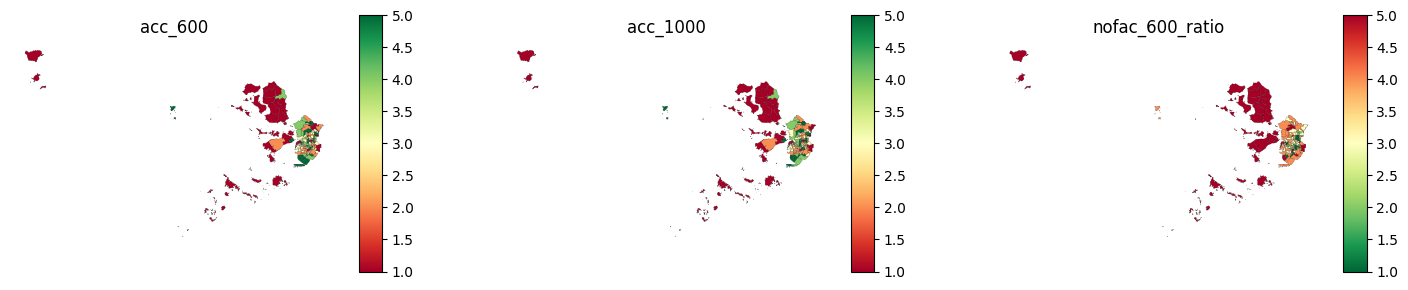

In [ ]:
#5. 지도로 점검
# [셀 A5] 동별 지수 5분위 지도 (1 = 하위 20%)
import matplotlib.pyplot as plt
bnd = gpd.read_file("dong_boundary.gpkg").to_crs(5179).astype({"adm_cd": str})
m = bnd.merge(dm[["adm_cd", "acc_600", "acc_1000", "nofac_600_ratio"]], on="adm_cd")
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
for a, c in zip(ax, ["acc_600", "acc_1000", "nofac_600_ratio"]):
    q = pd.qcut(m[c].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(float)
    m.assign(q=q).plot("q", cmap="RdYlGn" if c != "nofac_600_ratio" else "RdYlGn_r", legend=True, ax=a, edgecolor="k", linewidth=0.1)
    a.set_title(c); a.axis("off")
plt.show()

In [ ]:
n0 = int((dm["acc_600"] == 0).sum())
print("600m 지수 0인 동:", n0, "/ 전체 동:", len(dm), "/ 하위 20% 개수:", round(len(dm) * 0.2))
print(dm.loc[dm["acc_600"] == 0, "adm_nm"].tolist())

600m 지수 0인 동: 17 / 전체 동: 156 / 하위 20% 개수: 31
['용유동', '영종동', '불은면', '화도면', '양도면', '내가면', '하점면', '양사면', '송해면', '교동면', '삼산면', '서도면', '북도면', '백령면', '대청면', '덕적면', '자월면']


In [ ]:
# [셀 A6] K-means 입력: 섬 7개(정류장 자료 없음)는 도서형으로 빼고, 나머지 동의 세 변수 → 로그(왜도>1) → 표준화
from sklearn.preprocessing import StandardScaler
VARS = ["acc_600", "d_bus_w", "eld_single_ratio"]
dm["island"] = (dm["d_bus_w"] > 1000).astype(int)      # 섬 안 정류장이 없어 육지까지 거리가 잡힌 동
print("도서형으로 뺀 동:", dm.loc[dm["island"] == 1, "adm_nm"].tolist())
X = dm.loc[dm["island"] == 0, ["adm_cd", "adm_nm"] + VARS].dropna().copy()
print("K-means 대상 동:", len(X))
skew = X[VARS].skew(); LOG = [c for c in VARS if skew[c] > 1]
print("왜도:", skew.round(2).to_dict(), "→ 로그 변환:", LOG)
T = X[VARS].copy(); T[LOG] = np.log1p(T[LOG])
X[[c + "_z" for c in VARS]] = StandardScaler().fit_transform(T)
print(X[[c + "_z" for c in VARS]].corr().round(2).to_string())
X.to_csv("kmeans_input.csv", index=False, encoding="utf-8-sig")
dm.to_csv("dong_master.csv", index=False, encoding="utf-8-sig")
files.download("dong_master.csv"); files.download("kmeans_input.csv")

도서형으로 뺀 동: ['서도면', '북도면', '연평면', '백령면', '대청면', '덕적면', '자월면']
K-means 대상 동: 149
왜도: {'acc_600': 2.0, 'd_bus_w': 2.47, 'eld_single_ratio': 0.01} → 로그 변환: ['acc_600', 'd_bus_w']
                    acc_600_z  d_bus_w_z  eld_single_ratio_z
acc_600_z                1.00      -0.42               -0.23
d_bus_w_z               -0.42       1.00                0.08
eld_single_ratio_z      -0.23       0.08                1.00


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#d_bus_w 왜도 7.83은 확인이 필요
print(dm.sort_values("d_bus_w", ascending=False)[["adm_cd", "adm_nm", "d_bus_w", "acc_600"]].head(12).to_string())

       adm_cd adm_nm   d_bus_w  acc_600
151  23520330    백령면  136242.5   0.0000
152  23520340    대청면  133000.3   0.0000
150  23520320    연평면   46937.0   4.0404
153  23520350    덕적면   29451.1   0.0000
154  23520360    자월면   14948.6   0.0000
148  23510420    서도면    8392.8   0.0000
149  23520310    북도면    5314.7   0.0000
147  23510410    삼산면     395.3   0.0000
141  23510350    양도면     280.3   0.0000
138  23510320    불은면     272.0   0.0000
140  23510340    화도면     270.3   0.0000
139  23510330    길상면     259.8   0.3234
